# Лабораторная 4. Сравниваем эвристики A*

**Это заготовка для самостоятельного выполнения.** Рабочие части из твоей
третьей лабораторной уже перенесены. Карты, чтение файлов, измерения,
таблицы и построение графиков подготовлены.

Здесь A* ищет путь **по 8-связной сетке без срезания углов**.
Прямой шаг стоит 1, диагональный — √2.

## Что дописать

| Метка | Где | Что сделать |
|---|---|---|
| TODO 1 | `Map.get_neighbors` | Соседи в 8 направлениях; запрет срезания углов |
| TODO 2 | `compute_cost` | Стоимость прямого и диагонального шага |
| TODO 3 | `euclidean_distance` | Евклидова эвристика |
| TODO 4 | `octile_distance` | Диагональная эвристика |
| TODO 5 | `chebyshev_distance` | Эвристика Чебышёва |

Вместо `raise NotImplementedError(...)` впиши свой код. Манхэттенская
эвристика уже есть. Ещё нужно заполнить две текстовые ячейки: устройство
эксперимента и выводы по своим результатам.

**Порядок:** допиши пять мест → пройди проверки → посмотри пробный запуск →
включи полный эксперимент → напиши выводы. Пока задания не заполнены,
эксперименты аккуратно пропускаются. Заготовку можно выполнять сверху вниз.

После изменения функций перезапусти ядро и выполни ячейки сверху вниз: так в памяти не останутся старые определения.

## 1. Импорты и параметры — готово

Нужны те же библиотеки, что в третьей лабораторной, и `pandas` для таблиц.
Дополнительных установок из ноутбука нет.

Полный эксперимент по умолчанию выключен. Включи его после проверок и
пробного запуска: `RUN_FULL_BENCHMARK = True`, затем заново выполни эту
ячейку и ячейки эксперимента ниже.

In [1]:
from pathlib import Path
from time import perf_counter
from heapq import heappop, heappush
from typing import Tuple, List, Iterable, Callable, Type, Dict, Union, Optional
from datetime import datetime, timezone
import hashlib
import json
import math
import platform

import numpy as np
import numpy.typing as npt
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from PIL import Image, ImageDraw
from IPython.display import display

%matplotlib inline

SEED = 42
TASKS_PER_MAP = 100
REPEATS = 1
SMOKE_TASKS_PER_MAP = 3
TIE_BREAK = 'g_max'  # одинаковый для всех четырёх эвристик
RUN_FULL_BENCHMARK = False
PATH_TOL = 1e-5  # .scen хранит эталонную длину с конечной точностью

root_candidates = [
    Path.cwd(),
    Path.cwd() / 'lab04-benchmarking-astar',
    Path.cwd() / 'labs-astar' / 'lab04-benchmarking-astar',
]
BASE_DIR = next(
    (path for path in root_candidates if (path / 'data' / 'sources.json').is_file()),
    None,
)
if BASE_DIR is None:
    raise FileNotFoundError('Открой ноутбук из папки lab04-benchmarking-astar или labs-astar.')
DATA_DIR = BASE_DIR / 'data'
RESULTS_DIR = BASE_DIR / 'results'

HEURISTIC_ORDER = ['Euclidean', 'Octile', 'Chebyshev', 'Manhattan']
HEURISTIC_COLORS = {
    'Euclidean': '#4477AA', 'Octile': '#CCBB44',
    'Chebyshev': '#228833', 'Manhattan': '#AA3377',
}
plt.rcParams.update({
    'figure.dpi': 120, 'font.size': 10,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': False,
})

print('Python:', platform.python_version())
print('Данные:', DATA_DIR)
print('Полный эксперимент включён:', RUN_FULL_BENCHMARK)

Python: 3.12.3
Данные: D:\Disk_D\own\Python\alyouwant\labs-astar\lab04-benchmarking-astar\data
Полный эксперимент включён: False


## 2. Карта: добавь диагонали

### TODO 1 — `Map.get_neighbors`

Остальные методы `Map` перенесены из третьей лабораторной.

Верни список **пар координат `(ni, nj)`**, а не объектов `Node`.
Сосед должен находиться внутри карты и быть свободным.

Рассматривай 8 направлений. Диагональный ход разрешён, только если свободны
**обе** клетки сбоку от этой диагонали. Например, для хода из `(i, j)`
в `(i + 1, j + 1)` проверь ещё `(i + 1, j)` и `(i, j + 1)`.

Используй готовые `in_bounds` и `traversable`. Координаты — это
`i = строка`, `j = столбец`.

In [2]:
class Map:
    """
    Square grid map class represents the environment for our moving agent.

    Attributes
    ----------
    _width : int
        The number of columns in the grid

    _height : int
        The number of rows in the grid

    _cells : ndarray[int, ndim=2]
        The binary matrix, that represents the grid. 0 - cell is traversable, 1 - cell is blocked
    """

    def __init__(self, cells: npt.NDArray):
        """
        Initialization of map by 2d array of cells.

        Parameters
        ----------
        cells : ndarray[int, ndim=2]
            The binary matrix, that represents the grid. 0 - cell is traversable, 1 - cell is blocked.
        """
        self._width = cells.shape[1]
        self._height = cells.shape[0]
        self._cells = cells


    def in_bounds(self, i: int, j: int) -> bool:
        """
        Check if the cell (i, j) is on a grid.

        Parameters
        ----------
            i : int
                Number of the cell row in grid
            j : int
                Number of the cell column in grid
        Returns
        ----------
             bool
                Is the cell inside grid.
        """
        return (0 <= j < self._width) and (0 <= i < self._height)


    def traversable(self, i: int, j: int) -> bool:
        """
        Check if the cell (i, j) is not an obstacle.

        Parameters
        ----------
            i : int
                Number of the cell row in grid
            j : int
                Number of the cell column in grid
        Returns
        ----------
             bool
                Is the cell traversable.
        """
        return not self._cells[i, j]


    def get_neighbors(self, i: int, j: int) -> List[Tuple[int, int]]:
        """Соседи на 8-связной сетке без срезания углов."""
        # TODO 1: верни список свободных соседей с учётом диагоналей.
        raise NotImplementedError('TODO 1: Map.get_neighbors')


    def get_size(self) -> Tuple[int, int]:
        """
        Returns size of grid in cells.

        Returns
        ----------
            (height, widht) : Tuple[int, int]
                Number of rows and columns in grid
        """
        return (self._height, self._width)

### TODO 2 — `compute_cost`

Раньше стоимость каждого шага была 1. Теперь прямой шаг стоит 1,
а диагональный — `math.sqrt(2)`.

Функция считает только стоимость: стены и границы уже проверяет карта.
Для несовпадающих соседних клеток верни число. Для одинаковых клеток или
прыжка дальше одного шага выброси `ValueError`.

In [3]:
def compute_cost(i1: int, j1: int, i2: int, j2: int) -> Union[int, float]:
    # TODO 2: определи тип шага по разнице координат.
    raise NotImplementedError('TODO 2: compute_cost')

## 3. Твой рабочий код из третьей лабораторной — готово

Ниже перенесены `Node`, обе структуры OPEN/CLOSED, восстановление пути,
оба A* и два tie-break. Они уже заполнены.

**Единственная адаптация в циклах поиска:** вместо `g=node.g + 1`
используется `g=node.g + compute_cost(...)`. Стоимость диагонали теперь
вычислит твоя функция из TODO 2.

Для основного сравнения используем `astar_reexpansion` с одним фиксированным
tie-break. Так между четырьмя версиями меняется только эвристика.

In [4]:
class Node:
    """
    Node class represents a search node

    Attributes
    ----------
    i, j : int, int
        Coordinates of corresponding grid element.

    g : float | int
        g-value of the node.

    h : float | int
        h-value of the node // always 0 for Dijkstra.

    F : float | int
        f-value of the node // always equal to g-value for Dijkstra.

    parent : Node
        Pointer to the parent-node.
    """

    def __init__(
        self,
        i: int,
        j: int,
        g: Union[float, int] = 0,
        h: Union[float, int] = 0,
        f: Union[float, int] = None,
        parent: "Node" = None,
    ):
        """
        Initialization of search node.

        Parameters
        ----------
        i, j : int, int
            Coordinates of corresponding grid element.
        g : float | int
            g-value of the node.
        h : float | int
            h-value of the node // always 0 for Dijkstra.
        f : float | int
            f-value of the node // always equal to g-value for Dijkstra.
        parent : Node
            Pointer to the parent-node.
        """
        self.i = i
        self.j = j
        self.g = g
        self.h = h
        if f is None:
            self.f = self.g + h
        else:
            self.f = f
        self.parent = parent

    def __eq__(self, other):
        """
        Estimating where the two search nodes are the same,
        which is needed to detect dublicates in the search tree.
        """

        return (self.i == other.i) and (self.j == other.j)

    def __hash__(self):
        """
        To implement CLOSED as set/dict of nodes we need Node to be hashable.
        """

        return hash((self.i, self.j))

    def __lt__(self, other):
        """
        Comparing the keys (i.e. the f-values) of two nodes,
        which is needed to sort/extract the best element from OPEN.
        """

        return self.f < other.f

In [5]:
class SearchTreePQD:  # SearchTree which uses priority queue for OPEN and dict for CLOSED

    def __init__(self):
        self._open = []  # prioritized queue for the OPEN nodes
        self._closed = dict()  # dict for the expanded nodes = CLOSED
        self._enc_open_dublicates = 0  # the number of dublicates encountered in OPEN

    def __len__(self):
        """
        This gives the size of the search tree. Typically, we want to know
        the size of the search tree at the last iteration of the search
        to assess the memory footprint of the algorithm.
        """
        return len(self._open) + len(self._closed)

    def open_is_empty(self) -> bool:
        """
        open_is_empty should inform whether the OPEN is exhausted or not.
        In the former case the search main loop should be interrupted.
        """

        return len(self._open) == 0

    def add_to_open(self, item: Node):
        """
        Adding a (previously not expanded) node to the search-tree (i.e. to OPEN).
        It's either a totally new node (the one we never encountered before)
        or it can be a dublicate of the node that currently resides in OPEN.
        In this implementation we will detect dublicates lazily, thus at this
        point we dont care about them and just add a node to OPEN.
        """
        heappush(self._open, item)

    def get_best_node_from_open(self) -> Node:
        """
        Extracting the best node (i.e. the one with the minimal key) from OPEN.
        This node will be expanded further on in the main loop of the search.

        This is here where we must take care of the dublicates and discard the
        node if it was previously expanded (=resides in CLOSED) and take the next node.

        If OPEN becomes empty then we should return None.

        """
        while self._open:

            v = heappop(self._open)
            if v in self._closed:
                self._enc_open_dublicates += 1
            else:
                return v
        return None

    def add_to_closed(self, item: Node):

        self._closed[item] = item

    def was_expanded(self, item: Node) -> bool:

        return self._closed.get(item) is not None

    @property
    def opened(self):
        return self._open

    @property
    def expanded(self):
        return self._closed.values()

    @property
    def number_of_open_dublicates(self):
        return self._enc_open_dublicates

In [6]:
class SearchTreePQDReexp: # SearchTree with reexpansion which uses priority queue for OPEN and dict for CLOSED
    
    def __init__(self):
        self._open = []                 # prioritized queue for the OPEN nodes
        self._closed = dict()           # dict for the expanded (at least once) nodes = CLOSED
                                        # We need dict as we want to get access to the g-value of node in the container
                                        # and set() does not allow this.
        self._reexpanded = set()        # set for the nodes that were expanded at least twice
                                        # just for illustrative purposes
        self._reopened = set()          # set for the re-open nodes (just for the illustrative purposes)
        
        self._enc_open_dublicates = 0    # the number of dublicates encountered in OPEN
        self._number_of_reexpansions = 0 # the number of the re-expansions
                                      
    def __len__(self):
        """
        This gives the size of the search tree. Typically, we want to know 
        the size of the search tree at the last iteration of the search 
        to assess the memory footprint of the algorithm.
        """
        return len(self._open) + len(self._closed)
                
    def open_is_empty(self):
        """
        open_is_empty should inform whether the OPEN is exhausted or not.
        In the former case the search main loop should be interrupted.
        """
        
        return len(self._open) == 0
    
 
    def add_to_open(self, item: Node):
        """
        Adding a node to the search-tree (i.e. to OPEN). 
        It's either (1) a totally new node (the one we never encountered before)
        or (2) it can be a dublicate of the node that currently resides in OPEN
        or (3) a better version of the node that currently resides in CLOSED.
        
        The handling of the first two cases is the same as before - we just add the node to OPEN
        (as we will lazily detect dublicates in OPEN, i.e. when we retreive the best node from OPEN).
        
        In the third case, i.e. the new node has the lower g-value, we need to remove  
        the 'bad' dublicate from CLOSED first and only then push the new node to OPEN.
        For illustrative purposes we also add the new node to REOPENED in order to keep 
        track of such nodes.
        """
        
        
        
        old = self._closed.get(item)

        if old is not None:
            if item.g >= old.g:
                return
            del self._closed[item]
            self._reopened.add(item)

        heappush(self._open, item)
    

    def get_best_node_from_open(self) -> Optional[Node]:
        """
        Extracting the best node (i.e. the one with the minimal key) from OPEN.
        This node will be expanded further on in the main loop of the search.
        
        Here we must take care of the OPEN-dublicates and discard the
        node if it resides in CLOSED and take the next node.
        And repeat this process until we encouter the node that is not in CLOSED currently.
        If no such a node left in OPEN, we return None.
        
        Now if a valid node is encountered we need to check if it resides in REOPENED.
        If it is we add it to REEXPANDED (and increment the counter of the re-expanded nodes).
        This is needed for illustrative purposes only.
        """
                
        while self._open:

            v = heappop(self._open)
            if v in self._closed:
                self._enc_open_dublicates += 1
            else:
                if v in self._reopened:
                    self._reexpanded.add(v)
                    self._number_of_reexpansions += 1
                return v
        return None
    
    def add_to_closed(self, item: Node):
                
        self._closed[item] = item

        
    def was_expanded(self, item: Node) -> bool:
                
        return self._closed.get(item) is not None

    
    @property
    def opened(self):
        return self._open
    
    
    @property
    def expanded(self):
        return self._closed.values()

    
    @property
    def number_of_open_dublicates(self):
        return self._enc_open_dublicates
    
    
    @property
    def reexpanded(self):
        return self._reexpanded

    
    @property
    def number_of_reexpansions(self):
        return self._number_of_reexpansions


In [7]:
def make_path(goal: Node) -> Tuple[List[Node], Union[float, int]]:
    """
    Creates a path by tracing parent pointers from the goal node to the start node
    It also returns the path's length.
    
    Parameters
    ----------
    goal : Node
        Pointer to goal node in search tree.
        
    Returns
    ----------
    Tuple[List[Node], float|int]
        Path and length of the path.
    """

    length = goal.g
    current = goal
    path = []
    while current.parent:
        path.append(current)
        current = current.parent
    path.append(current)
    return path[::-1], length


In [8]:
def astar(
    task_map: Map,
    start_i: int,
    start_j: int,
    goal_i: int,
    goal_j: int,
    heuristic_func: Callable,
    search_tree: Type[SearchTreePQD],
) -> Tuple[
    bool, Optional[Node], int, int, Optional[Iterable[Node]], Optional[Iterable[Node]]
]:
    """
    Implementation of A* algorithm.
    """
    ast = search_tree()  # A* search tree
    steps = 0
    search_tree_size = 0

    start_node = Node(
        start_i, start_j, g=0, h=heuristic_func(start_i, start_j, goal_i, goal_j)
    )
    ast.add_to_open(start_node)

    while not ast.open_is_empty():
        steps += 1
        node = ast.get_best_node_from_open()
        if node is None:
            break
        search_tree_size = len(ast)
        if node.i == goal_i and node.j == goal_j:
            return True, node, steps, search_tree_size, ast.opened, ast.expanded
        else:
            ast.add_to_closed(node)
            for neighbor in task_map.get_neighbors(node.i, node.j):
                neighbor_node = Node(
                    neighbor[0],
                    neighbor[1],
                    g=node.g + compute_cost(node.i, node.j, neighbor[0], neighbor[1]),
                    h=heuristic_func(neighbor[0], neighbor[1], goal_i, goal_j),
                    parent=node,
                )
                if not ast.was_expanded(neighbor_node):
                    ast.add_to_open(neighbor_node)

    CLOSED = ast.expanded
    search_tree_size = len(ast)
    return False, None, steps, search_tree_size, None, CLOSED

In [9]:
def astar_reexpansion(task_map: Map, 
             start_i: int, start_j: int, 
             goal_i: int, goal_j: int, 
             heuristic_func: Callable, 
             search_tree: Type[SearchTreePQDReexp]) -> Tuple[bool, 
                                                        Optional[Node], 
                                                        int, 
                                                        int, 
                                                        Optional[Iterable[Node]], 
                                                        Optional[Iterable[Node]],
                                                        Optional[Iterable[Node]]]:
    """
    Implementation of A* algorithm with node reexpansion.
    """ 
    ast = search_tree()
    steps = 0
    search_tree_size = 0
    
    start_node = Node(start_i, start_j, g=0, h=heuristic_func(start_i, start_j, goal_i, goal_j))
    ast.add_to_open(start_node)
    while not ast.open_is_empty():
        steps += 1
        node = ast.get_best_node_from_open()
        if node is None:
            break
        search_tree_size = len(ast)
        if node.i == goal_i and node.j == goal_j:
            return True, node, steps, search_tree_size, ast.opened, ast.expanded, ast.reexpanded
        else:
            ast.add_to_closed(node)
            for neighbor in task_map.get_neighbors(node.i, node.j):
                neighbor_node = Node(
                    neighbor[0],
                    neighbor[1],
                    g=node.g + compute_cost(node.i, node.j, neighbor[0], neighbor[1]),
                    h=heuristic_func(neighbor[0], neighbor[1], goal_i, goal_j),
                    parent=node,
                )
                ast.add_to_open(neighbor_node)            
    
        
    CLOSED = ast.expanded
    search_tree_size = len(ast)
    return False, None, steps, search_tree_size, None, CLOSED, ast.reexpanded

In [10]:
def lt_g_max(self, other):
    if self.f == other.f:
        return self.g > other.g
    return self.f < other.f
        
    
def lt_g_min(self, other):
    if self.f == other.f:
        return self.g < other.g
    return self.f < other.f

In [11]:
if TIE_BREAK == 'g_max':
    Node.__lt__ = lt_g_max
elif TIE_BREAK == 'g_min':
    Node.__lt__ = lt_g_min
else:
    raise ValueError('TIE_BREAK должен быть g_max или g_min')

## 4. Четыре эвристики

### Манхэттенская — твоя, уже готова

На 4-связной сетке она была допустимой. Здесь диагональ дешевле двух
прямых шагов, поэтому Манхэттен может **завышать** расстояние. Мы оставляем
его в эксперименте специально и проверяем оптимальность по эталону.

In [12]:
def manhattan_distance(i1: int, j1: int, i2: int, j2: int) -> Union[int, float]:
    """
    Implementation of Manhattan heuristic.
    
    Parameters
    ----------
        i1, j1 : int, int
            (i, j) coordinates of the first cell row on grid.
        i2, j2 : int, int
            (i, j) coordinates of the second cell row on grid.
    
    Returns
    ----------
    int | float
        Manhattan distance between two cells.
    """

    return abs(i1 - i2) + abs(j1 - j2)


### TODO 3 — Евклидова эвристика

Расстояние между клетками по прямой, как на обычной координатной плоскости.
Используй разности координат и теорему Пифагора.

In [13]:
def euclidean_distance(i1: int, j1: int, i2: int, j2: int) -> Union[int, float]:
    # TODO 3
    raise NotImplementedError('TODO 3: euclidean_distance')

### TODO 4 — Диагональная эвристика (Octile)

Представь путь на пустой сетке: сначала делаем столько диагональных шагов,
сколько позволяют обе разности координат, затем идём прямо по оставшейся
оси. Учти стоимость каждого вида шага.

In [14]:
def octile_distance(i1: int, j1: int, i2: int, j2: int) -> Union[int, float]:
    # TODO 4
    raise NotImplementedError('TODO 4: octile_distance')

### TODO 5 — Эвристика Чебышёва

Представь, что диагональный шаг тоже стоит 1. Сколько шагов нужно королю
на пустой шахматной доске? Это и будет оценкой; стен она не учитывает.

In [15]:
def chebyshev_distance(i1: int, j1: int, i2: int, j2: int) -> Union[int, float]:
    # TODO 5
    raise NotImplementedError('TODO 5: chebyshev_distance')

In [16]:
HEURISTICS = {
    'Euclidean': euclidean_distance,
    'Octile': octile_distance,
    'Chebyshev': chebyshev_distance,
    'Manhattan': manhattan_distance,
}

## 5. Маленькие проверки — готово

Проверяем границы, свободную диагональ, запрет диагонали при **одной**
боковой стене и при двух стенах, стоимость шагов и значения эвристик.

Сообщение «НЕ ЗАПОЛНЕНО» ожидаемо для заготовки. «ОШИБКА» означает,
что код уже есть, но проверка не прошла. Пока хотя бы одна проверка
не прошла, поиск и эксперименты ниже не запускаются.

In [17]:
def check_neighbors():
    empty = Map(np.zeros((3, 3), dtype=np.int8))
    expected = {(i, j) for i in range(3) for j in range(3)} - {(1, 1)}
    actual = empty.get_neighbors(1, 1)
    assert set(actual) == expected, 'В центре пустой карты должно быть 8 соседей'
    assert len(actual) == len(set(actual)), 'Соседи не должны повторяться'
    assert set(empty.get_neighbors(0, 0)) == {(0, 1), (1, 0), (1, 1)}, 'Проверь границы'
    for walls in [[(0, 1)], [(1, 0)], [(0, 1), (1, 0)]]:
        cells = np.zeros((2, 2), dtype=np.int8)
        for i, j in walls:
            cells[i, j] = 1
        neighbors = Map(cells).get_neighbors(0, 0)
        assert (1, 1) not in neighbors, 'Диагональ нельзя проводить через боковую стену'
        assert all(cells[i, j] == 0 for i, j in neighbors), 'Нельзя ходить на стену'
    assert Map(np.zeros((1, 1), dtype=np.int8)).get_neighbors(0, 0) == []


def check_cost():
    for di, dj in [(0, 1), (0, -1), (1, 0), (-1, 0)]:
        assert math.isclose(compute_cost(2, 2, 2 + di, 2 + dj), 1)
    for di, dj in [(1, 1), (1, -1), (-1, 1), (-1, -1)]:
        assert math.isclose(compute_cost(2, 2, 2 + di, 2 + dj), math.sqrt(2))
    for end in [(2, 2), (4, 2), (3, 4)]:
        try:
            compute_cost(2, 2, *end)
        except ValueError:
            continue
        raise AssertionError('Для нулевого шага и прыжка нужен ValueError')


def check_heuristic(func, expected):
    assert math.isclose(func(0, 0, 3, 4), expected), 'Неверное расстояние для (0, 0) → (3, 4)'
    assert func(2, 5, 2, 5) == 0, 'В цели оценка должна быть нулевой'
    assert math.isclose(func(3, 4, 0, 0), expected), 'Проверь симметрию и модули'
    assert math.isclose(func(1, 2, 1, 7), 5), 'Проверь движение по одной оси'


def check_implementations():
    checks = [
        ('TODO 1: соседи', check_neighbors),
        ('TODO 2: стоимость', check_cost),
        ('TODO 3: Евклид', lambda: check_heuristic(euclidean_distance, 5)),
        ('TODO 4: Octile', lambda: check_heuristic(octile_distance, 1 + 3 * math.sqrt(2))),
        ('TODO 5: Чебышёв', lambda: check_heuristic(chebyshev_distance, 4)),
    ]
    ready = True
    for name, check in checks:
        try:
            check()
        except NotImplementedError:
            ready = False
            print('НЕ ЗАПОЛНЕНО —', name)
        except Exception as exc:
            ready = False
            print('ОШИБКА —', name, ':', type(exc).__name__, str(exc))
        else:
            print('OK —', name)
    return ready


IMPLEMENTATIONS_READY = check_implementations()

НЕ ЗАПОЛНЕНО — TODO 1: соседи
НЕ ЗАПОЛНЕНО — TODO 2: стоимость
НЕ ЗАПОЛНЕНО — TODO 3: Евклид
НЕ ЗАПОЛНЕНО — TODO 4: Octile
НЕ ЗАПОЛНЕНО — TODO 5: Чебышёв


## 6. Данные MovingAI — уже скачаны, интернет для запуска не нужен

Используем три карты из **трёх разных коллекций**:

| Карта | Коллекция | Размер, строки × столбцы |
|---|---|---|
| `arena.map` | Dragon Age: Origins | 49 × 49 |
| `ht_chantry.map` | Dragon Age 2 | 141 × 162 |
| `AR0021SR.map` | Baldur's Gate II, исходные размеры | 64 × 60 |

Ниже можно увидеть их устройство. Карты небольшие, чтобы эксперименты
на ноутбуке оставались посильными. Их можно заменить другими парами
`.map` / `.scen` из коллекции, изменив `MAP_SPECS`.

Файл `.map` хранит карту, `.scen` — пары старт/цель и эталонные длины.
В сценариях координаты записаны как **x, y**; загрузчик сам переводит
их в привычные **i, j = y, x**. Эталон уже учитывает диагонали √2 и запрет
срезания углов. Результаты сравниваются с ним с допуском `PATH_TOL`,
а не через `int`, как в третьей лабораторной.

Источники: [MovingAI](https://movingai.com/benchmarks/grids.html),
[форматы файлов и правила движения](https://movingai.com/benchmarks/formats.html).
Точные ссылки, дата скачивания и SHA-256 — в `data/sources.json`.

In [18]:
MAP_SPECS = [
    {'name': 'arena', 'collection': 'dao', 'map_file': 'arena.map', 'scen_file': 'arena.map.scen'},
    {'name': 'ht_chantry', 'collection': 'da2', 'map_file': 'ht_chantry.map', 'scen_file': 'ht_chantry.map.scen'},
    {'name': 'AR0021SR', 'collection': 'bgmaps', 'map_file': 'AR0021SR.map', 'scen_file': 'AR0021SR.map.scen'},
]


def load_movingai_map(path):
    lines = Path(path).read_text(encoding='utf-8').splitlines()
    if lines[0].strip() != 'type octile' or lines[3].strip() != 'map':
        raise ValueError(f'Неизвестный формат карты: {path}')
    height, width = int(lines[1].split()[1]), int(lines[2].split()[1])
    rows = lines[4:]
    if len(rows) != height or any(len(row) != width for row in rows):
        raise ValueError(f'Размер карты не совпадает с заголовком: {path}')
    chars = set(''.join(rows))
    if not chars <= set('.G@OT'):
        raise ValueError(f'Здесь поддерживаются обычные карты без особых типов местности: {chars}')
    cells = np.array([[0 if char in '.G' else 1 for char in row] for row in rows], dtype=np.int8)
    return Map(cells)


def load_movingai_scenarios(path, expected_map, grid_map):
    lines = Path(path).read_text(encoding='utf-8').splitlines()
    if not lines[0].startswith('version '):
        raise ValueError(f'Нет заголовка scenario: {path}')
    tasks = []
    height, width = grid_map.get_size()
    for task_id, line in enumerate(lines[1:]):
        if not line.strip():
            continue
        parts = line.split()
        if len(parts) != 9:
            raise ValueError(f'В строке scenario должно быть 9 полей: {line}')
        bucket, map_name, map_width, map_height, sx, sy, gx, gy, optimal = parts
        if Path(map_name).name != expected_map or (int(map_height), int(map_width)) != (height, width):
            raise ValueError('Сценарий относится к другой карте или масштабу')
        start, goal = (int(sy), int(sx)), (int(gy), int(gx))
        for i, j in [start, goal]:
            if not grid_map.in_bounds(i, j) or not grid_map.traversable(i, j):
                raise ValueError('Старт или цель лежит за картой либо на стене')
        length = float(optimal)
        if not math.isfinite(length) or length < 0:
            raise ValueError('Некорректная эталонная длина')
        tasks.append({'task_id': task_id, 'bucket': int(bucket), 'start': start, 'goal': goal, 'optimal_length': length})
    return tasks


maps, all_tasks = {}, {}
for spec in MAP_SPECS:
    folder = DATA_DIR / spec['collection']
    grid_map = load_movingai_map(folder / spec['map_file'])
    maps[spec['name']] = grid_map
    all_tasks[spec['name']] = load_movingai_scenarios(folder / spec['scen_file'], spec['map_file'], grid_map)

with (DATA_DIR / 'sources.json').open(encoding='utf-8') as file:
    DATA_SOURCES = json.load(file)
for source in DATA_SOURCES['files']:
    current_hash = hashlib.sha256((BASE_DIR / source['path']).read_bytes()).hexdigest()
    if current_hash != source['sha256']:
        raise ValueError(f"Изменился файл данных: {source['path']}")
print('Загружено карт:', len(maps))

Загружено карт: 3


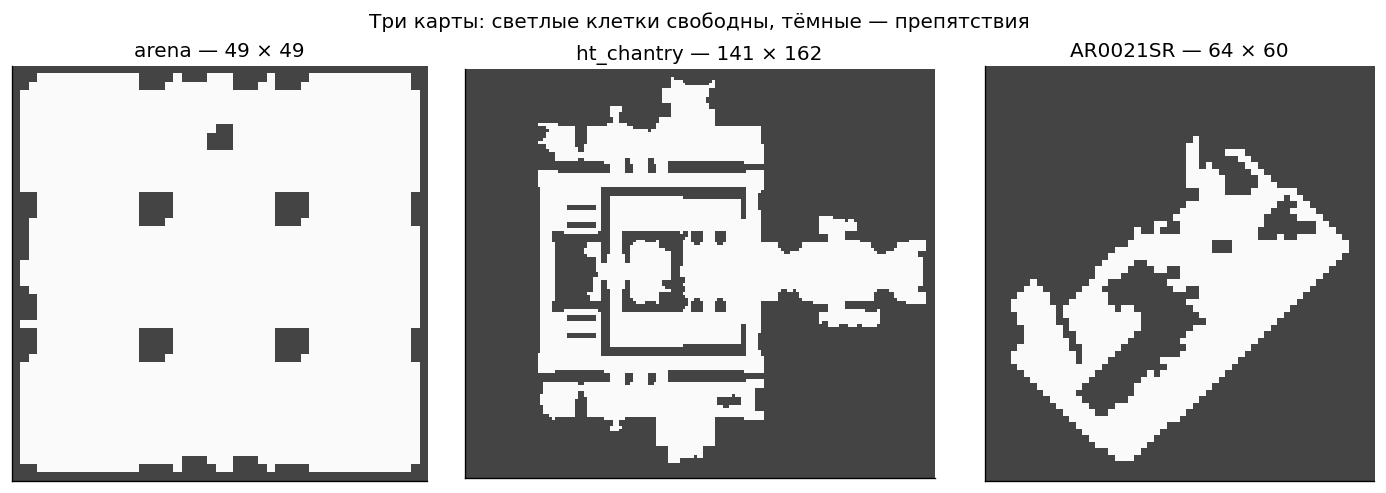

In [19]:
fig, axes = plt.subplots(1, len(maps), figsize=(12, 4), constrained_layout=True)
for ax, (name, grid_map) in zip(np.atleast_1d(axes), maps.items()):
    ax.imshow(grid_map._cells, cmap=ListedColormap(['#FAFAFA', '#444444']), vmin=0, vmax=1, interpolation='nearest')
    height, width = grid_map.get_size()
    ax.set_title(f'{name} — {height} × {width}')
    ax.set_xticks([])
    ax.set_yticks([])
fig.suptitle('Три карты: светлые клетки свободны, тёмные — препятствия')
plt.show()

## 7. Выбор задач разной сложности — готово

На каждой карте выбираются 100 задач без повторов. Сначала сортируем их
по эталонной длине и делим на пять примерно равных групп. Затем берём
одинаковое число случайных задач из каждой группы с фиксированным seed.
Так в выборку входят и короткие, и длинные маршруты.

Длина — **приближение сложности**: длинный маршрут не обязательно требует
больше раскрытий. Каждая эвристика получает одни и те же выбранные задачи.
При `TASKS_PER_MAP = 100` и `REPEATS = 1` полный эксперимент содержит
3 × 100 × 4 = **1200 измеряемых запусков**.

In [20]:
def select_tasks(tasks, n, seed):
    if n < 5 or n > len(tasks):
        raise ValueError(f'Нужно от 5 до {len(tasks)} задач, получено {n}')
    ordered = sorted(tasks, key=lambda task: (task['optimal_length'], task['task_id']))
    bins = np.array_split(np.arange(len(ordered)), 5)
    quotas = [n // 5 + (index < n % 5) for index in range(5)]
    rng = np.random.default_rng(seed)
    chosen = []
    for group, (indices, quota) in enumerate(zip(bins, quotas), start=1):
        if quota > len(indices):
            raise ValueError('Недостаточно задач в одной из групп длины')
        for index in rng.choice(indices, size=quota, replace=False):
            chosen.append({**ordered[int(index)], 'length_group': group})
    return sorted(chosen, key=lambda task: (task['optimal_length'], task['task_id']))


tasks_by_map = {
    spec['name']: select_tasks(all_tasks[spec['name']], TASKS_PER_MAP, SEED + index)
    for index, spec in enumerate(MAP_SPECS)
}
selected_tasks_table = pd.DataFrame([
    {'map': name, **task} for name, tasks in tasks_by_map.items() for task in tasks
])
display(selected_tasks_table.groupby('map', sort=False).agg(
    tasks=('task_id', 'size'), shortest=('optimal_length', 'min'), longest=('optimal_length', 'max'),
).round(3))

,tasks,shortest,longest
map,,,
arena,100,1.414,51.841
ht_chantry,100,1.414,181.539
AR0021SR,100,1.000,67.284


### TODO текст 1 — описание эксперимента

Перепиши своими словами и дополни:

- Какие три карты выбраны? Чем визуально отличается их устройство?
- Почему выбран такой размер карт и по 100 задач?
- Как отбирались задачи и что фиксирует seed?
- Какие эвристики и какой tie-break сравниваются?
- Как проверяется кратчайший путь и что означают показатели ниже?

**Мой текст:** …

## 8. Один маршрут и пробный запуск

Сначала посмотри один путь с Octile. Проверка маршрута контролирует
старт, цель, препятствия, допустимость каждого шага и сумму стоимостей.
Это помогает не принять неверный путь за правильный только из-за
совпадения длины.

Рисование перенесено из третьей лабораторной. Оно не входит в замеры.

In [21]:
def draw(grid_map: Map, 
         start: Node = None, 
         goal: Node = None, 
         path: Iterable[Node] = None, 
         nodes_discovered: Iterable[Node] = None, 
         nodes_expanded: Iterable[Node] = None, 
         nodes_reexpanded: Iterable[Node] = None):
    """
    Auxiliary function that visualizes the environment, the path and 
    the expanded/not yet expanded/re-expanded nodes.
    Re-expansions are not happening in Dijkstra, but still...
    
    The function assumes that nodes_discovered/nodes_expanded/nodes_reexpanded
    are iterable collestions of search nodes.
    
    Parameters
    ----------
    grid_map : Map
        Environment representation in for of grid.
    start, goal : Node, Node
        Nodes for start and goal positions of agent
    path : Iterable[Node] 
        Sequence of nodes, which represents the path between start ang goal cells.
    nodes_discovered : Iterable[Node] 
        Nodes, which were discovered during search process.
    nodes_expanded : Iterable[Node]
        Nodes, which were expanded during search process.
    nodes_reexpanded : Iterable[Node]
        Nodes, which were reexpanded during search process.
    """
    scale = 5
    height, width = grid_map.get_size()
    h_im = height * scale
    w_im = width * scale
    im = Image.new('RGB', (w_im, h_im), color = 'white')
    draw = ImageDraw.Draw(im)
    
    for i in range(height):
        for j in range(width):
            if(not grid_map.traversable(i, j)):
                draw.rectangle((j * scale, i * scale, (j + 1) * scale - 1, (i + 1) * scale - 1), fill=( 70, 80, 80 ))

    if nodes_discovered is not None:
        for node in nodes_discovered:
            draw.rectangle((node.j * scale, node.i * scale, (node.j + 1) * scale - 1, (node.i + 1) * scale - 1), fill=(213, 219, 219), width=0)
    
    if nodes_expanded is not None:
        for node in nodes_expanded:
            draw.rectangle((node.j * scale, node.i * scale, (node.j + 1) * scale - 1, (node.i + 1) * scale - 1), fill=(131, 145, 146), width=0)
    
    if nodes_reexpanded is not None:
        for node in nodes_reexpanded:
                draw.rectangle((node.j * scale, node.i * scale, (node.j + 1) * scale - 1, (node.i + 1) * scale - 1), fill=(255, 145, 146), width=0)
    
    if path is not None:
        for step in path:
            if (step is not None):
                if (grid_map.traversable(step.i, step.j)):
                    draw.rectangle((step.j * scale, step.i * scale, (step.j + 1) * scale - 1, (step.i + 1) * scale - 1), fill=(52, 152, 219), width=0)
                else:
                    draw.rectangle((step.j * scale, step.i * scale, (step.j + 1) * scale - 1, (step.i + 1) * scale - 1), fill=(230, 126, 34), width=0)

    if (start is not None) and (grid_map.traversable(start.i, start.j)):
        draw.rectangle((start.j * scale, start.i * scale, (start.j + 1) * scale - 1, (start.i + 1) * scale - 1), fill=(40, 180, 99), width=0)
    
    if (goal is not None) and (grid_map.traversable(goal.i, goal.j)):
        draw.rectangle((goal.j * scale, goal.i * scale, (goal.j + 1) * scale - 1, (goal.i + 1) * scale - 1), fill=(231, 76, 60), width=0)
        
    _, ax = plt.subplots(dpi=150)
    ax.axes.xaxis.set_visible(False)
    ax.axes.yaxis.set_visible(False)
    plt.imshow(np.asarray(im))
    plt.show()

In [22]:
def validate_path(grid_map, task, path, reported_length):
    if not path or (path[0].i, path[0].j) != task['start'] or (path[-1].i, path[-1].j) != task['goal']:
        return False
    total = 0.0
    for node in path:
        if not grid_map.in_bounds(node.i, node.j) or not grid_map.traversable(node.i, node.j):
            return False
    for previous, current in zip(path, path[1:]):
        if (current.i, current.j) not in grid_map.get_neighbors(previous.i, previous.j):
            return False
        total += compute_cost(previous.i, previous.j, current.i, current.j)
    return math.isclose(total, reported_length, rel_tol=1e-9, abs_tol=PATH_TOL)


if IMPLEMENTATIONS_READY:
    demo_map_name = MAP_SPECS[0]['name']
    demo_task = tasks_by_map[demo_map_name][TASKS_PER_MAP // 2]
    demo_result = astar_reexpansion(
        maps[demo_map_name], *demo_task['start'], *demo_task['goal'], octile_distance, SearchTreePQDReexp,
    )
    assert demo_result[0], 'На демонстрационной задаче путь должен существовать'
    demo_path, demo_length = make_path(demo_result[1])
    assert validate_path(maps[demo_map_name], demo_task, demo_path, demo_length), 'Маршрут некорректен'
    assert math.isclose(demo_length, demo_task['optimal_length'], abs_tol=PATH_TOL, rel_tol=1e-9), 'Длина отличается от эталона'
    draw(maps[demo_map_name], Node(*demo_task['start']), Node(*demo_task['goal']), demo_path, *demo_result[4:])
    print('Длина:', round(demo_length, 5), 'Эталон:', demo_task['optimal_length'])
else:
    print('Маршрут появится после заполнения TODO 1–5 и повторного выполнения проверок.')

Маршрут появится после заполнения TODO 1–5 и повторного выполнения проверок.


## 9. Измерения — готово

Сохраняем отдельно: найден ли путь, корректен ли маршрут и совпала ли длина
с эталоном. **Успех в этой работе — корректный кратчайший путь.**

Число раскрытий считает небольшой наследник твоего класса: один вызов
`add_to_closed` — одно раскрытие. Повторные раскрытия тоже учитываются.
Это не размер CLOSED, поскольку одну клетку можно раскрывать несколько раз.

Время измеряется через `perf_counter` только вокруг поиска: без чтения
карт, проверки пути и рисования. Порядок эвристик перемешивается с seed.
Перед замерами делается один прогрев на карту и эвристику.

`REPEATS` — число повторов каждой пары задача/эвристика. Если повторов
несколько, перед сводкой время сводится к медиане на задачу. Разброс на
графиках относится к **разным задачам**, а не к доверительному интервалу.

In [23]:
class SearchTreeMeasured(SearchTreePQDReexp):
    def __init__(self):
        super().__init__()
        self.expansion_count = 0

    def add_to_closed(self, item):
        super().add_to_closed(item)
        self.expansion_count += 1


def run_benchmark(task_sets, limit=None, repeats=1):
    if not isinstance(repeats, int) or repeats < 1:
        raise ValueError('Число повторов должно быть положительным целым')
    rows = []
    rng = np.random.default_rng(SEED)
    for map_name, selected in task_sets.items():
        # Для пробного запуска берём равномерно по всей выборке, а не только самые короткие.
        indices = np.arange(len(selected)) if limit is None else np.linspace(0, len(selected) - 1, min(limit, len(selected)), dtype=int)
        tasks = [selected[int(index)] for index in indices]
        grid_map = maps[map_name]
        warmup = tasks[0]
        for heuristic in HEURISTICS.values():
            astar_reexpansion(grid_map, *warmup['start'], *warmup['goal'], heuristic, SearchTreeMeasured)
        for number, task in enumerate(tasks, start=1):
            for repetition in range(repeats):
                names = list(HEURISTICS)
                rng.shuffle(names)
                for heuristic_name in names:
                    tree = SearchTreeMeasured()
                    started = perf_counter()
                    result = astar_reexpansion(
                        grid_map, *task['start'], *task['goal'], HEURISTICS[heuristic_name], lambda: tree,
                    )
                    elapsed = perf_counter() - started
                    found = bool(result[0])
                    path, length = make_path(result[1]) if found else ([], np.nan)
                    valid = found and validate_path(grid_map, task, path, length)
                    optimal = valid and math.isclose(length, task['optimal_length'], rel_tol=1e-9, abs_tol=PATH_TOL)
                    rows.append({
                        'map': map_name, 'task_id': task['task_id'], 'length_group': task['length_group'],
                        'heuristic': heuristic_name, 'repeat': repetition + 1,
                        'optimal_length': task['optimal_length'], 'path_length': length,
                        'found': found, 'path_valid': valid, 'optimal': optimal,
                        'expansions': tree.expansion_count,
                        'reexpansions': tree.number_of_reexpansions,
                        'time_ms': elapsed * 1000,
                    })
            if number % 10 == 0 or number == len(tasks):
                print(f'{map_name}: {number}/{len(tasks)} задач; все 4 эвристики')
    return pd.DataFrame(rows)


def aggregate_repeats(raw):
    return raw.groupby(['map', 'task_id', 'heuristic'], sort=False, as_index=False).agg(
        length_group=('length_group', 'first'), optimal_length=('optimal_length', 'first'),
        path_length=('path_length', 'first'), found=('found', 'all'),
        path_valid=('path_valid', 'all'), optimal=('optimal', 'all'),
        expansions=('expansions', 'median'), reexpansions=('reexpansions', 'median'),
        time_ms=('time_ms', 'median'), repeats=('repeat', 'size'),
    )

In [24]:
smoke_raw = None
if IMPLEMENTATIONS_READY:
    smoke_raw = run_benchmark(tasks_by_map, limit=SMOKE_TASKS_PER_MAP, repeats=1)
    display(smoke_raw.groupby(['map', 'heuristic'], sort=False).agg(
        tasks=('task_id', 'size'), shortest_path_rate=('optimal', 'mean'), mean_time_ms=('time_ms', 'mean'),
    ).round(3))
    print('Это пробный запуск; его недостаточно для сдачи полного эксперимента.')
else:
    print('Пробный запуск пропущен: сначала заполни TODO 1–5 и выполни проверки.')

Пробный запуск пропущен: сначала заполни TODO 1–5 и выполни проверки.


## 10. Полный эксперимент

После успешных проверок и пробного запуска включи
`RUN_FULL_BENCHMARK = True` в параметрах. Все 100 задач на каждую карту
обязательны для итогового сравнения. Отдельный прогрев в эти 1200 запусков
не включён. По мере работы выводится прогресс каждые 10 задач.

Результаты сохраняются в `results/` рядом с ноутбуком. Они появятся только
после реального запуска — в заготовке нет заранее придуманных результатов.

In [25]:
results_raw = None
results = None
summary = None
if not IMPLEMENTATIONS_READY:
    print('Полный эксперимент пропущен: не все TODO прошли проверки.')
elif not RUN_FULL_BENCHMARK:
    print('Для полного эксперимента включи RUN_FULL_BENCHMARK в параметрах.')
else:
    assert len(MAP_SPECS) >= 3 and len({spec['collection'] for spec in MAP_SPECS}) >= 3
    assert TASKS_PER_MAP >= 100, 'Для итогового эксперимента нужно не менее 100 задач на карту'
    results_raw = run_benchmark(tasks_by_map, repeats=REPEATS)
    results = aggregate_repeats(results_raw)
    expected = len(MAP_SPECS) * TASKS_PER_MAP * len(HEURISTICS)
    assert len(results) == expected, 'Не все пары задача/эвристика измерены'
    RESULTS_DIR.mkdir(exist_ok=True)
    results_raw.to_csv(RESULTS_DIR / 'benchmark_raw.csv', index=False)
    results.to_csv(RESULTS_DIR / 'benchmark_by_task.csv', index=False)
    selected_tasks_table.to_csv(RESULTS_DIR / 'selected_tasks.csv', index=False)
    metadata = {
        'created_utc': datetime.now(timezone.utc).isoformat(),
        'seed': SEED, 'tasks_per_map': TASKS_PER_MAP, 'repeats': REPEATS,
        'tie_break': TIE_BREAK, 'path_tolerance': PATH_TOL,
        'heuristics': list(HEURISTICS), 'maps': MAP_SPECS,
        'python': platform.python_version(), 'numpy': np.__version__,
        'pandas': pd.__version__, 'matplotlib': matplotlib.__version__,
        'data_sources': DATA_SOURCES,
    }
    (RESULTS_DIR / 'experiment.json').write_text(json.dumps(metadata, ensure_ascii=False, indent=2), encoding='utf-8')
    print('Сохранено измеряемых запусков:', len(results_raw))
    display(results.head(8).round(4))

Полный эксперимент пропущен: не все TODO прошли проверки.


## 11. Сводная таблица — готово

`optimal_rate_pct` — процент задач с корректным кратчайшим путём.
`found_rate_pct` — процент задач, где вообще найден путь.
Они могут различаться, особенно для Манхэттена.

Для времени и числа раскрытий показаны среднее, стандартное отклонение,
медиана и квартили. Карты рассматриваем отдельно: у них разные размеры
и устройство. Итоговые цифры включают и неудачные попытки; не сравнивай
скорость в отрыве от качества результата.

In [26]:
if results is not None:
    summary = results.groupby(['map', 'heuristic'], sort=False).agg(
        tasks=('task_id', 'size'), found_rate_pct=('found', lambda x: 100 * x.mean()),
        optimal_rate_pct=('optimal', lambda x: 100 * x.mean()),
        time_mean_ms=('time_ms', 'mean'), time_std_ms=('time_ms', 'std'),
        time_median_ms=('time_ms', 'median'),
        time_q25_ms=('time_ms', lambda x: x.quantile(.25)), time_q75_ms=('time_ms', lambda x: x.quantile(.75)),
        expansions_mean=('expansions', 'mean'), expansions_std=('expansions', 'std'),
        expansions_median=('expansions', 'median'),
        expansions_q25=('expansions', lambda x: x.quantile(.25)), expansions_q75=('expansions', lambda x: x.quantile(.75)),
    )
    display(summary.round(3))
    summary.to_csv(RESULTS_DIR / 'summary.csv')
else:
    print('Сводка появится после полного эксперимента.')

Сводка появится после полного эксперимента.


## 12. Графики — код готов

Сначала сравни качество, затем время и число раскрытий. На boxplot линия
внутри коробки — медиана, коробка — от 25-го до 75-го процентиля,
усы — до 1,5 межквартильных размахов, отдельные точки — более удалённые
наблюдения. Это разброс **между задачами**, а не доверительный интервал.

На графиках времени и раскрытий у карт самостоятельные оси Y: сравнивай
четыре эвристики **внутри одной карты**. Обозначения: Euclid — Евклид,
Octile — диагональная, Cheb. — Чебышёв, Manh. — Манхэттен.

In [27]:
def plot_benchmark(per_task):
    map_names = [spec['name'] for spec in MAP_SPECS]
    short_labels = ['Euclid', 'Octile', 'Cheb.', 'Manh.']
    colors = [HEURISTIC_COLORS[name] for name in HEURISTIC_ORDER]

    fig, axes = plt.subplots(1, len(map_names), figsize=(14, 4), constrained_layout=True, sharey=True)
    for ax, map_name in zip(np.atleast_1d(axes), map_names):
        part = per_task[per_task['map'] == map_name]
        rates = [100 * part.loc[part['heuristic'] == name, 'optimal'].mean() for name in HEURISTIC_ORDER]
        bars = ax.bar(short_labels, rates, color=colors, edgecolor='#333333', linewidth=.6)
        for bar, rate in zip(bars, rates):
            ax.text(bar.get_x() + bar.get_width() / 2, rate + 1.5, f'{rate:.0f}%', ha='center', fontsize=9)
        ax.set_title(f'{map_name}: {part.task_id.nunique()} задач')
        ax.set_ylim(0, 112)
        ax.set_yticks([0, 25, 50, 75, 100])
        ax.grid(axis='y', alpha=.2)
        ax.set_axisbelow(True)
    np.atleast_1d(axes)[0].set_ylabel('Кратчайший корректный путь, % задач')
    fig.suptitle('Успешность поиска по эвристикам')
    plt.show()

    for metric, ylabel, title in [
        ('time_ms', 'Время поиска, мс', 'Распределение времени поиска по задачам'),
        ('expansions', 'Число раскрытий', 'Распределение числа раскрытий по задачам'),
    ]:
        fig, axes = plt.subplots(1, len(map_names), figsize=(14, 4), constrained_layout=True)
        for ax, map_name in zip(np.atleast_1d(axes), map_names):
            part = per_task[per_task['map'] == map_name]
            data = [part.loc[part['heuristic'] == name, metric].to_numpy() for name in HEURISTIC_ORDER]
            artists = ax.boxplot(data, patch_artist=True, medianprops={'color': '#222222', 'linewidth': 1.5},
                                 flierprops={'marker': '.', 'markersize': 3, 'alpha': .45})
            for box, color in zip(artists['boxes'], colors):
                box.set_facecolor(color)
                box.set_alpha(.7)
            ax.set_xticks(range(1, 5), short_labels)
            ax.set_title(map_name)
            ax.set_ylabel(ylabel)
            ax.set_ylim(bottom=0)
            ax.grid(axis='y', alpha=.2)
        fig.suptitle(title + ' — оси Y отдельные для каждой карты')
        plt.show()


if results is not None:
    plot_benchmark(results)
else:
    print('Графики появятся после полного эксперимента.')

Графики появятся после полного эксперимента.


## 13. TODO текст 2 — твои выводы

Пиши по полученным таблицам и графикам, а не по предполагаемому результату.

1. Какие эвристики находили кратчайший путь во всех задачах? Что получилось у Манхэттена?
2. Какая эвристика потребовала меньше раскрытий на каждой карте?
3. Какая была быстрее? Совпадает ли это с числом раскрытий?
4. Насколько велик разброс? Что скрывает одно среднее значение?
5. Меняется ли сравнение в зависимости от карты? С чем в её устройстве это может быть связано?
6. Какие ограничения у эксперимента: три небольшие карты, выбор задач по длине, один или несколько замеров времени?

**Мои выводы:** …

## Перед сдачей

- [ ] Заполнены пять мест для кода, все маленькие проверки прошли.
- [ ] Проверен пример маршрута.
- [ ] Выполнен полный эксперимент: минимум 3 коллекции × 100 задач × 4 эвристики.
- [ ] В таблицах есть качество, время, раскрытия, среднее и разброс.
- [ ] Графики отображаются, оси и единицы понятны.
- [ ] Написаны описание эксперимента и выводы.
- [ ] Ноутбук выполнен сверху вниз и сохранён с реальными результатами.

## Источники

- Условия: соседний `README.md` (исходное задание).
- Твой код: `../lab03-astar/lab03_astar.ipynb`.
- [MovingAI: Benchmarks for Grid-Based Pathfinding](https://movingai.com/benchmarks/grids.html).
- [Форматы .map и .scen](https://movingai.com/benchmarks/formats.html).
- N. Sturtevant, *Benchmarks for Grid-Based Pathfinding*, IEEE Transactions on
  Computational Intelligence and AI in Games, 4(2), 144–148, 2012.
- Данные MovingAI: [Open Data Commons Attribution License](https://opendatacommons.org/licenses/by/1-0/).
  Исходные файлы сохранены без изменений; см. `data/sources.json`.